In [1]:
import sys
import os

# la racine du projet
project_root = os.path.abspath('..')
if project_root not in sys.path:
    sys.path.append(project_root)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from src.O3_radiomics.feature_extractor import EmbolismFeatureExtractor
from src.O3_radiomics.feature_selector import RadiomicsFeatureSelector

print("✅ Modules chargés avec succès !")


✅ Modules chargés avec succès !


- Chargement des données des Patients (Patient 001)

📊 PAT001 chargé ! Volume : (201, 512, 512) | Voxels pathologiques: 19054


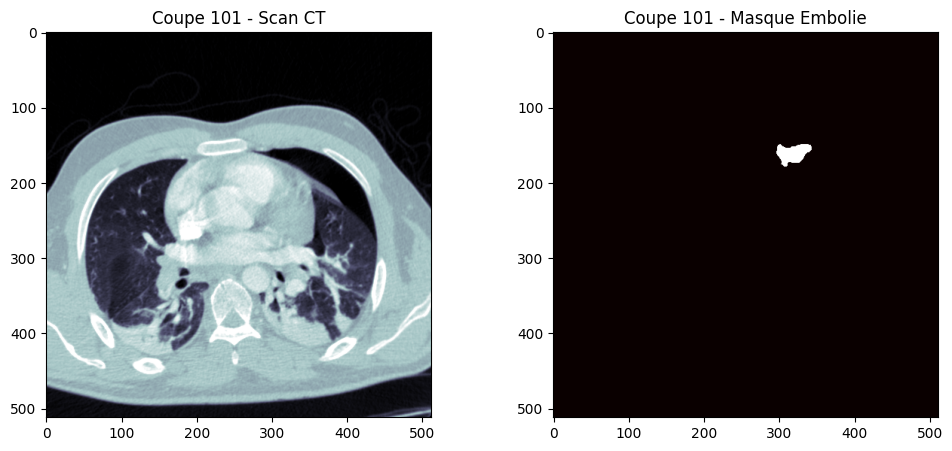

In [3]:
import os

patient_id = "PAT001"
# project_root donne le chemin absolu
vol_path = os.path.join(project_root, f"data/processed/{patient_id}/volume.npy")
mask_path = os.path.join(project_root, f"data/processed/{patient_id}/mask.npy")

# Chargement
volume_hu = np.load(vol_path)
masque = np.load(mask_path)

print(f"📊 {patient_id} chargé ! Volume : {volume_hu.shape} | Voxels pathologiques: {masque.sum()}")

# Astuce : on trouve automatiquement la coupe (slice Z) où l'embolie est la plus visible
z_indices = np.where(masque > 0)[0]
slice_z = int(np.median(z_indices)) if len(z_indices) > 0 else volume_hu.shape[0] // 2

# Visualisation des vraies données
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.title(f"Coupe {slice_z} - Scan CT")
plt.imshow(volume_hu[slice_z, :, :], cmap='bone')
plt.subplot(1, 2, 2)
plt.title(f"Coupe {slice_z} - Masque Embolie")
plt.imshow(masque[slice_z, :, :], cmap='hot')
plt.show()


- Extraction Radiomique sur le(s) patient(s)

In [4]:
print("🚀 Lancement de l'extraction radiomique...")
extractor = EmbolismFeatureExtractor()

# L'extraction sur un vrai volume peut prendre 1 ou 2 secondes selon la taille du caillot
features = extractor.extract_from_arrays(volume_hu, masque)

# Transposé sous format tableau
df_candidat = pd.DataFrame([features])
print(f"\n✅ {len(features)} caractéristiques extraites du vrai patient !")

pd.set_option('display.max_columns', None) # Pour ne masquer aucune colonne
display(df_candidat.T) # Affichage transposé


INFO:src.O3_radiomics.feature_extractor:✅ Extracteur léger (scikit-image) initialisé.


🚀 Lancement de l'extraction radiomique...

✅ 20 caractéristiques extraites du vrai patient !


,0
intensity_mean,0.287665
intensity_median,0.058571
intensity_std,0.350448
intensity_variance,0.122814
intensity_min,0.000000
intensity_max,1.000000
intensity_skewness,0.835923
intensity_kurtosis,-0.989245
intensity_entropy,3.187963
shape_volume_mm3,14381.000000



## 2. Simulation d'une Cohorte (Matrice Normalisée & Sélection)

("Matrice de caractéristiques normalisée"), nous devons simuler la création d'une matrice sur un ensemble de candidats (Embolies vs Faux Positifs). 

Ensuite, nous appliquerons le `RadiomicsFeatureSelector` pour éviter le sur-apprentissage (élimination des variances faibles, forte corrélation et sélection via Random Forest).

1. Création d'une matrice simulée de 100 candidats (50 EP, 50 Bruit)...
Dimension de la matrice brute : (100, 20)

2. Normalisation des données (StandardScaler)...
Aperçu de la matrice normalisée (5 premières lignes) :


,intensity_mean,intensity_median,intensity_std,intensity_variance,intensity_min,intensity_max,intensity_skewness,intensity_kurtosis,intensity_entropy,shape_volume_mm3,shape_major_axis_length,shape_minor_axis_length,shape_elongation,shape_surface_area_mm2,shape_sphericity,texture_contrast,texture_dissimilarity,texture_homogeneity,texture_energy,texture_correlation
0,0.374540,-0.199787,0.583275,1.585038,-0.313790,-0.147506,1.572372,0.671260,-0.496170,0.348913,-0.468574,-0.404265,0.281929,-1.990621,-1.832685,-0.516364,-0.997081,0.267987,-1.138926,-1.693649
1,1.417607,-0.285179,0.042850,-1.442476,-0.658503,0.207265,-1.008816,0.255102,-0.645123,-0.421318,-0.632186,1.559784,-0.004765,-1.151438,0.616237,-1.144895,0.222206,-2.195505,-1.596108,0.061101
2,0.634789,0.102345,-0.127780,-0.288437,-1.696479,-0.646884,-0.356142,0.979007,0.427196,-1.779748,0.463130,-0.335933,-0.749305,0.485974,0.816628,0.909110,-0.823810,-0.407450,0.209555,0.910234
3,-0.676013,-0.246033,-1.050615,-1.207752,0.849235,1.487632,0.011275,0.922077,0.447657,-0.747621,0.507274,1.293527,-0.029824,1.420689,-2.692899,0.804719,0.100630,-0.396394,-0.051051,-2.320960
4,-0.396656,0.283589,1.356620,-0.511478,-0.951972,-0.422659,0.944793,0.205228,-0.564632,0.321868,0.194555,0.811081,-0.777509,-0.435373,-0.551431,-1.376503,0.309291,0.210361,-0.145332,-0.409382


INFO:src.O3_radiomics.feature_selector:✅ Sélecteur initialisé : variance=0.01, correlation=0.9, top_k=10
INFO:src.O3_radiomics.feature_selector:🚀 Démarrage sélection de features...
INFO:src.O3_radiomics.feature_selector:📊 Variance: 20 → 20 features
INFO:src.O3_radiomics.feature_selector:📊 Corrélation (>0.9): 20 → 20 features



3. Sélection de caractéristiques (RadiomicsFeatureSelector)...


INFO:src.O3_radiomics.feature_selector:📊 Random Forest: 20 → 10 features
INFO:src.O3_radiomics.feature_selector:✅ Sélection terminée: 20 → 10 features



Dimension de la matrice finale après sélection : (100, 10)
Cette matrice est enfin prête pour l'entrainement des modèles classiques (Objectif 4) !

4. Visualisation de l'importance des caractéristiques


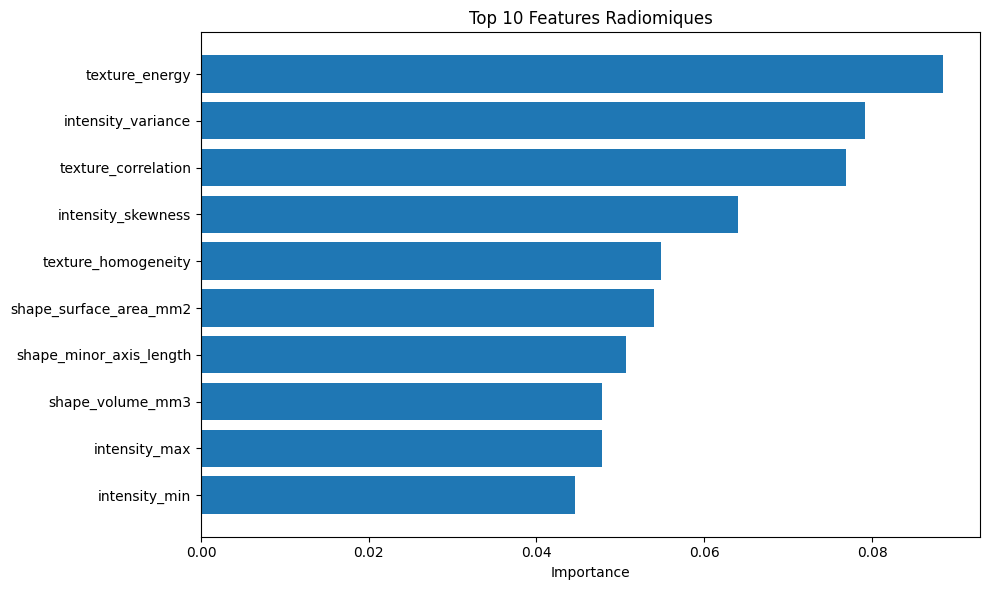

In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from src.O3_radiomics.feature_selector import RadiomicsFeatureSelector
import matplotlib.pyplot as plt

print("1. Création d'une matrice simulée de 100 candidats (50 EP, 50 Bruit)...")
# On duplique le candidat extrait en ajoutant du bruit pour simuler 100 candidats
base_features = list(features.values())
feature_names = list(features.keys())

n_samples = 100
np.random.seed(42)
X_simulated = np.array([base_features for _ in range(n_samples)])
# Ajout de variation aléatoire (bruit) aux features pour les distinguer
X_simulated = X_simulated + np.random.normal(0, 0.5, X_simulated.shape)

# Simulation des labels (y) : 1 = Embolie Pulmonaire (EP), 0 = Non-EP (Faux Positif)
y_simulated = pd.Series(np.random.randint(0, 2, n_samples))

# Transformation en DataFrame (C'est ça la fameuse Matrice de Caractéristiques)
df_matrice = pd.DataFrame(X_simulated, columns=feature_names)
print(f"Dimension de la matrice brute : {df_matrice.shape}\n")

print("2. Normalisation des données (StandardScaler)...")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_matrice)
df_scaled = pd.DataFrame(X_scaled, columns=feature_names)
print("Aperçu de la matrice normalisée (5 premières lignes) :")
display(df_scaled.head())

print("\n3. Sélection de caractéristiques (RadiomicsFeatureSelector)...")
# On instancie le sélecteur (On garde le Top 10 des features)
selector = RadiomicsFeatureSelector(variance_threshold=0.01, correlation_threshold=0.90, top_k_features=10)

# Application de la sélection
df_selected = selector.select(df_scaled, y_simulated)

print(f"\nDimension de la matrice finale après sélection : {df_selected.shape}")
print("Cette matrice est enfin prête pour l'entrainement des modèles classiques (Objectif 4) !")

print("\n4. Visualisation de l'importance des caractéristiques")
selector.plot_importance(top_n=10)
